# Assignment II (Set B) – Robust Reinforcement Learning under Sticky Actuators
### Group 103 – Q_learning_SARSA

**Group Contribution Declaration**

| S.No | Name | Contribution |
|---|---|---|
| 1 | SHEKHAR AGGARWAL | 25% |
| 2 | ANSH HANDA | 25% |
| 3 | VIDYA P.R | 25% |
| 4 | SURYAWANSHI AMIT BALASAHEB | 25% |

**What this notebook does**

1. Builds a modified `MountainCar-v0` with a *sticky actuator* (30% chance that a change of command is ignored), an energy penalty for every selected push and a +25 bonus for a gentle arrival at the flag (Part a).
2. Verifies the wrapper with a replay of the example from the problem statement, random-policy statistics and hand-coded policies (Part a).
3. Trains tabular Q-learning (Part b) and tabular SARSA (Part c) on the original and on the modified environment under identical settings.
4. Compares the four agents with training curves, Q-value curves, policy maps and a 100-episode greedy test (Part d).
5. Discusses the results (Part e). Appendix A re-checks the chosen bins and α against a few alternatives.

All runs use the same master seed (**103**, our group number), so re-running the notebook top to bottom gives the same numbers.

## 0. Setup
`gymnasium` is not part of the default Anaconda installation in the virtual lab, so the first cell installs it only if it is missing.

In [3]:
# check whether gymnasium is available and install it only if it is missing
import importlib.util, subprocess, sys

if importlib.util.find_spec("gymnasium") is None:      # None means the package is not installed
    # install into the python of the running kernel (needs internet once)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gymnasium"])
    print("gymnasium installed")
else:
    print("gymnasium already available")

gymnasium installed


In [4]:
# standard libraries
import time, platform, socket, datetime, math

# scientific stack available in the lab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

# the RL environment library
import gymnasium as gym

# show wide tables without line breaks
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def stamp(label):
    '''Print date, time and machine name. Called at the start/end of every part so that the
    screenshots taken in the virtual lab show when and where the code was executed.'''
    now = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")   # current local date and time
    print(f"[{now}] host={socket.gethostname()} | {label}")       # host name of the lab machine


# print library versions so the run can be reproduced later
print("python    :", platform.python_version())
print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("gymnasium :", gym.__version__)
print("matplotlib:", plt.matplotlib.__version__)
stamp("Setup finished")

Matplotlib is building the font cache; this may take a moment.


python    : 3.12.7
numpy     : 1.26.4
pandas    : 2.2.3
gymnasium : 1.4.0
matplotlib: 3.10.1
[2026-11-01 11:25:08] host=ip-10-3-24-18.ap-south-1.compute.internal | Setup finished


---
# Part (a) – Modified Environment Implementation and Verification

The wrapper below follows the six steps of the problem statement in the same order:

1. store the agent's action `a`,
2. sticky actuator: if `a != a_prev`, draw `r ~ U[0,1)` and replace `a` by `a_prev` when `r < 0.30`; then `a_prev = a_exec`,
3. execute `a_exec` in the original environment,
4. `R = R_base - 0.3 * 1[a != 1] + B` (penalty uses the **selected** action `a`),
5. `B = +25` only if `terminated and not truncated and x >= 0.5 and v <= 0.03`,
6. return `obs, R, terminated, truncated, info` with `info` untouched.

Design notes
* The wrapper has its own random generator, seeded from the seed passed to `reset()`. We use `np.random.default_rng([seed, 2])` so that its stream is different from the agent's stream `default_rng([seed, 1])`. If both were created from the same integer, the "sticky" draws and the ε-greedy draws would be exactly the same numbers.
* For testing only, a uniform-number source can be injected (`uniform_source`) and a per-step `trace` list can be switched on. The trace is kept inside the wrapper object; the agent never reads it, and nothing is added to `obs` or `info`.

In [6]:
class StickyMountainCar(gym.Wrapper):
    '''MountainCar-v0 with a sticky actuator, an energy penalty and a gentle-arrival bonus.

    env            : the original environment, gym.make("MountainCar-v0")
    p_stick        : probability that a *change* of action is ignored (0.30)
    push_penalty   : cost subtracted whenever the agent selects action 0 or 2 (0.3)
    bonus          : reward added for a gentle arrival (+25)
    v_gentle       : maximum velocity at the flag that still counts as gentle (0.03)
    uniform_source : optional function returning numbers in [0,1); only used in the tests
    keep_trace     : if True every step is stored in self.trace (tests only, agent never sees it)
    '''

    def __init__(self, env, p_stick=0.30, push_penalty=0.3, bonus=25.0, v_gentle=0.03,
                 uniform_source=None, keep_trace=False):
        '''Store the settings and create the internal variable a_prev.'''
        super().__init__(env)                   # keeps observation_space and action_space of env
        self.p_stick = p_stick                  # 30 % stuck probability
        self.push_penalty = push_penalty        # energy cost per selected push
        self.bonus = bonus                      # gentle arrival bonus
        self.v_gentle = v_gentle                # speed limit for a gentle arrival
        self.goal_x = 0.5                       # flag position of MountainCar
        self.uniform_source = uniform_source    # scripted numbers for the replay test
        self.keep_trace = keep_trace            # switch for the verification log
        self.trace = []                         # verification log (stays inside the wrapper)
        self.rng = np.random.default_rng()      # actuator noise, re-seeded in reset()
        self.a_prev = 1                         # action executed on the previous step

    def reset(self, seed=None, options=None):
        '''Reset the base env and the actuator memory (a_prev = 1, "do not accelerate").'''
        if seed is not None:                                  # a new seed also fixes the actuator
            self.rng = np.random.default_rng([seed, 2])       # own stream (agent uses [seed, 1])
        self.a_prev = 1                                       # rule: a_prev = 1 after every reset
        return self.env.reset(seed=seed, options=options)    # obs and info passed on unchanged

    def _uniform(self):
        '''Return one number from U[0,1): scripted in the tests, otherwise from self.rng.'''
        if self.uniform_source is not None:      # test mode: take the next scripted number
            return self.uniform_source()
        return self.rng.random()                 # normal mode: uniform random number

    def step(self, action):
        '''Apply the sticky actuator, step the base environment and reshape the reward.'''
        # Step 1: store the action chosen by the agent before anything changes it
        a = int(action)
        prev = self.a_prev                          # kept only for the trace

        # Step 2: sticky actuator
        r = None                                    # no random number if a == a_prev
        a_exec = a                                  # by default the selected action is executed
        if a != self.a_prev:                        # only a *change* of command can get stuck
            r = self._uniform()                     # r ~ U[0,1)
            if r < self.p_stick:                    # stuck relay: keep doing the old action
                a_exec = self.a_prev
        self.a_prev = a_exec                        # memory holds the action really executed

        # Step 3: execute a_exec in the original MountainCar
        obs, r_base, terminated, truncated, info = self.env.step(a_exec)

        # Step 5 (needed inside step 4): gentle arrival bonus, all four conditions together
        gentle = (terminated and not truncated
                  and obs[0] >= self.goal_x and obs[1] <= self.v_gentle)
        B = self.bonus if gentle else 0.0

        # Step 4: modified reward, the penalty depends on the SELECTED action a
        penalty = self.push_penalty if a != 1 else 0.0
        reward = r_base - penalty + B

        # optional log for the verification part (not returned to the agent)
        if self.keep_trace:
            self.trace.append(dict(a_prev=prev, a=a, r=r, a_exec=a_exec, r_base=r_base,
                                   penalty=penalty, B=B, R=reward,
                                   x=float(obs[0]), v=float(obs[1]),
                                   terminated=terminated, truncated=truncated))

        # Step 6: same tuple as the original env, info is not modified
        return obs, reward, terminated, truncated, info


def make_env(modified, **wrapper_kwargs):
    '''Create the original MountainCar-v0 (modified=False) or the sticky version (modified=True).'''
    base = gym.make("MountainCar-v0")           # includes the 200-step TimeLimit of the original
    if modified:                                # wrap only for the modified environment
        return StickyMountainCar(base, **wrapper_kwargs)
    return base


stamp("Wrapper defined")

[2026-11-01 11:25:08] host=ip-10-3-24-18.ap-south-1.compute.internal | Wrapper defined


### (a.1) Replaying the example table from the problem statement
We inject the same random numbers as the table (0.62, –, 0.27, 0.81, 0.18) and feed the same agent actions (0, 0, 2, 2, 1). The wrapper must produce the executed actions 0, 0, 0, 2, 2.

In [8]:
class ScriptedUniform:
    '''Hands out pre-defined numbers one by one; used to reproduce the example table exactly.'''

    def __init__(self, numbers):
        '''numbers: the list of "random" numbers to return in order.'''
        self.numbers = list(numbers)     # queue of numbers to hand out
        self.used = 0                    # how many have been consumed so far

    def __call__(self):
        '''Return the next number of the list.'''
        value = self.numbers[self.used]  # next number in the list
        self.used += 1                   # move the pointer forward
        return value


# example from the assignment
agent_actions = [0, 0, 2, 2, 1]                        # actions chosen by the agent
expected_exec = [0, 0, 0, 2, 2]                        # executed actions given in the table
scripted = ScriptedUniform([0.62, 0.27, 0.81, 0.18])   # step 2 repeats, so it uses no number

env_demo = make_env(True, uniform_source=scripted, keep_trace=True)
env_demo.reset(seed=0)                                 # a_prev starts at 1
for act in agent_actions:                              # play the five agent actions
    env_demo.step(act)

# build the same table as in the assignment from the wrapper trace
cols = ["a_prev", "a", "r", "a_exec", "r_base", "penalty", "B", "R"]
demo = pd.DataFrame(env_demo.trace)[cols]
demo.index = np.arange(1, len(demo) + 1)               # step numbers 1..5
demo["r"] = ["-" if pd.isna(z) else z for z in demo["r"]]   # "-" where no number was drawn
demo["expected a_exec"] = expected_exec
print(demo.to_string())
print("\nAll executed actions match the assignment table:", list(demo["a_exec"]) == expected_exec)
print("Random numbers consumed:", scripted.used, "(the repeated action in step 2 drew none)")
env_demo.close()

   a_prev  a     r  a_exec  r_base  penalty    B    R  expected a_exec
1       1  0  0.62       0    -1.0      0.3  0.0 -1.3                0
2       0  0     -       0    -1.0      0.3  0.0 -1.3                0
3       0  2  0.27       0    -1.0      0.3  0.0 -1.3                0
4       0  2  0.81       2    -1.0      0.3  0.0 -1.3                2
5       2  1  0.18       2    -1.0      0.0  0.0 -1.0                2

All executed actions match the assignment table: True
Random numbers consumed: 4 (the repeated action in step 2 drew none)


### (a.2) Random-policy statistics
We run 300 episodes with a uniformly random policy (60 000 steps) and count, from the wrapper trace:
* how many attempted changes (`a != a_prev`) were replaced by `a_prev` → should be ≈ 30 %,
* how many repeats (`a == a_prev`) were replaced → must be exactly 0,
* whether `R - R_base - B` equals `-0.3·1[a≠1]` on **every** step, split by what was selected and what was executed.

In [10]:
def run_policy_with_trace(policy, n_episodes, seed0, p_stick=0.30):
    '''Run policy(obs, rng) on the modified env for n_episodes; return the step trace.'''
    env = make_env(True, p_stick=p_stick, keep_trace=True)
    rng = np.random.default_rng(seed0)                 # rng used by the policy itself
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed0 + ep)            # different but fixed seed per episode
        done = False
        while not done:                                # play until terminated or truncated
            obs, R, term, trunc, info = env.step(policy(obs, rng))
            done = term or trunc
        env.trace[-1]["episode_end"] = True            # mark the last step of the episode
    env.close()
    df = pd.DataFrame(env.trace)
    df["episode_end"] = df["episode_end"].eq(True)     # True only on the final step
    df["episode"] = df["episode_end"].shift(fill_value=False).cumsum()   # episode number per step
    return df


def random_policy(obs, rng):
    '''Uniformly random action, ignores the observation.'''
    return int(rng.integers(3))


trace_rand = run_policy_with_trace(random_policy, n_episodes=300, seed0=1000)
print("steps recorded:", len(trace_rand), "| episodes:", trace_rand["episode"].nunique())

steps recorded: 60000 | episodes: 300


In [11]:
# --- sticky actuator statistics ---
changes = trace_rand[trace_rand["a"] != trace_rand["a_prev"]]    # agent tried to change action
repeats = trace_rand[trace_rand["a"] == trace_rand["a_prev"]]    # agent repeated the action
n_chg, n_rep = len(changes), len(repeats)
is_stuck = changes["a_exec"] == changes["a_prev"]                # change ignored
stuck = int(is_stuck.sum())
stuck_rep = int((repeats["a_exec"] != repeats["a"]).sum())       # any change of a repeated action
draws_on_repeat = int(repeats["r"].notna().sum())                # numbers drawn on repeats

p_hat = stuck / n_chg                                            # observed replacement rate
se = math.sqrt(p_hat * (1 - p_hat) / n_chg)                      # binomial standard error
z = (p_hat - 0.30) / math.sqrt(0.30 * 0.70 / n_chg)              # distance from 0.30 in std units
print(f"attempted changes      : {n_chg}")
print(f"replaced by a_prev     : {stuck}  ->  rate = {p_hat:.4f}")
print(f"95% CI of the rate     : {p_hat - 1.96 * se:.4f} .. {p_hat + 1.96 * se:.4f}"
      f"   (z = {z:.2f} against 0.30)")
print(f"repeated actions       : {n_rep}")
print(f"replaced among repeats : {stuck_rep}   random numbers drawn on repeats: {draws_on_repeat}")
ok_exec = ((changes["a_exec"] == changes["a"]) | is_stuck).all()
print(f"on a change, a_exec is always either a or a_prev: {ok_exec}")

# the rule itself: on a change the old action must be kept exactly when r < 0.30
rule_ok = ((changes["r"] < 0.30) == is_stuck).all()
print(f"\nreplacement happened exactly when r < 0.30 (every change step): {rule_ok}")
print(f"share of drawn numbers below 0.30: {(changes['r'] < 0.30).mean():.4f}"
      f"   mean of drawn numbers: {changes['r'].mean():.4f} (0.5 expected)")

# stuck rate in 10 batches of 30 episodes, to see the normal sampling spread
batch_id = changes["episode"] // 30                               # 30 episodes per batch
batch_rate = is_stuck.groupby(batch_id).mean()
print("\nstuck rate per batch of 30 episodes:", np.round(batch_rate.values, 3))
print(f"batch mean {batch_rate.mean():.4f}, min {batch_rate.min():.4f}, max {batch_rate.max():.4f}")

# the stuck rate should not depend on which change was attempted
by_pair = (changes.assign(stuck=is_stuck)
                  .groupby(["a_prev", "a"])["stuck"].agg(["count", "mean"])
                  .rename(columns={"count": "attempts", "mean": "stuck rate"}))
print("\nStuck rate for every (a_prev -> a) transition:")
print(by_pair.round(4).to_string())

attempted changes      : 40090
replaced by a_prev     : 11811  ->  rate = 0.2946
95% CI of the rate     : 0.2901 .. 0.2991   (z = -2.35 against 0.30)
repeated actions       : 19910
replaced among repeats : 0   random numbers drawn on repeats: 0
on a change, a_exec is always either a or a_prev: True

replacement happened exactly when r < 0.30 (every change step): True
share of drawn numbers below 0.30: 0.2946   mean of drawn numbers: 0.5034 (0.5 expected)

stuck rate per batch of 30 episodes: [0.29  0.294 0.287 0.289 0.303 0.29  0.3   0.297 0.291 0.305]
batch mean 0.2946, min 0.2869, max 0.3054

Stuck rate for every (a_prev -> a) transition:
          attempts  stuck rate
a_prev a                      
0      1      6726      0.2991
       2      6559      0.2897
1      0      6754      0.2865
       2      6752      0.2943
2      0      6652      0.3004
       1      6647      0.2977


In [12]:
# --- energy penalty check ---
t = trace_rand.copy()
t["observed_penalty"] = -(t["R"] - t["r_base"] - t["B"])     # penalty recovered from the reward
t["expected_penalty"] = np.where(t["a"] != 1, 0.3, 0.0)       # rule: depends on selected action


def case_name(row):
    '''Describe a step by what the agent selected and what was really executed.'''
    sel = "push" if row["a"] != 1 else "no-push(1)"          # selected action type
    exe = "push" if row["a_exec"] != 1 else "no-push(1)"     # executed action type
    stuck_flag = "stuck" if row["a_exec"] != row["a"] else "executed"
    return f"selected {sel:10s} | executed {exe:10s} | {stuck_flag}"


t["case"] = t.apply(case_name, axis=1)                         # label every step
penalty_table = (t.groupby("case")
                   .agg(steps=("R", "size"),
                        mean_penalty=("observed_penalty", "mean"),
                        min_penalty=("observed_penalty", "min"),
                        max_penalty=("observed_penalty", "max"))
                   .round(6))
print(penalty_table.to_string())
mismatch = int((np.abs(t["observed_penalty"] - t["expected_penalty"]) > 1e-9).sum())
print(f"\nSteps where penalty != 0.3*1[a != 1] : {mismatch} out of {len(t)}")
print("Row 'selected no-push(1) | executed push | stuck': the actuator kept pushing,")
print("but no penalty was charged because the agent selected action 1.")

                                                      steps  mean_penalty  min_penalty  max_penalty
case                                                                                               
selected no-push(1) | executed no-push(1) | executed  16188           0.0         -0.0         -0.0
selected no-push(1) | executed push       | stuck      3991           0.0         -0.0         -0.0
selected push       | executed no-push(1) | stuck      3922           0.3          0.3          0.3
selected push       | executed push       | executed  32001           0.3          0.3          0.3
selected push       | executed push       | stuck      3898           0.3          0.3          0.3

Steps where penalty != 0.3*1[a != 1] : 0 out of 60000
Row 'selected no-push(1) | executed push | stuck': the actuator kept pushing,
but no penalty was charged because the agent selected action 1.


### (a.3) Components that must stay unchanged
* observation and action spaces are compared with the original env,
* `info` returned by the wrapper is compared with `info` from the original env,
* **dynamics**: we run the wrapper with random commands, replay the actions it actually *executed* in a second, original env with the same seed, and compare states, base rewards and the terminated/truncated flags. With `p_stick = 0` the executed actions are the selected ones, so this is a direct comparison; with `p_stick = 0.3` it shows that the only change is which action gets executed.

In [14]:
base_env = make_env(False)
wrap_env = make_env(True)
same_obs = base_env.observation_space == wrap_env.observation_space
same_act = base_env.action_space == wrap_env.action_space
print("observation space equal:", same_obs, "->", wrap_env.observation_space)
print("action space equal     :", same_act, "->", wrap_env.action_space)

_, info_b = base_env.reset(seed=5)                  # same seed for both envs
_, info_w = wrap_env.reset(seed=5)
_, _, _, _, info_b2 = base_env.step(2)              # same action for both envs
_, _, _, _, info_w2 = wrap_env.step(2)
print("info on reset equal    :", info_b == info_w, info_w)
print("info on step equal     :", info_b2 == info_w2, info_w2)


def compare_with_base(p_stick, seed, n_steps=400):
    '''Random commands to the wrapper, the EXECUTED actions to the original env; compare outputs.'''
    w = make_env(True, p_stick=p_stick, keep_trace=True)
    b = make_env(False)
    rng = np.random.default_rng(seed)
    obs_w, _ = w.reset(seed=seed)
    obs_b, _ = b.reset(seed=seed)
    max_diff, flags_equal, rbase_equal = np.abs(obs_w - obs_b).max(), True, True
    for _ in range(n_steps):
        obs_w, R, tw, uw, _ = w.step(int(rng.integers(3)))     # random command, sticky env
        a_exec = w.trace[-1]["a_exec"]                         # what the wrapper executed
        obs_b, rb, tb, ub, _ = b.step(a_exec)                  # same action, original env
        max_diff = max(max_diff, np.abs(obs_w - obs_b).max())  # largest state difference
        flags_equal &= (tw == tb) and (uw == ub)               # same termination flags
        rbase_equal &= (w.trace[-1]["r_base"] == rb)           # same base reward
        if tw or uw:                                           # restart both with a new seed
            seed += 1
            obs_w, _ = w.reset(seed=seed)
            obs_b, _ = b.reset(seed=seed)
    return max_diff, flags_equal, rbase_equal


for p in [0.0, 0.30]:
    d, f, rb = compare_with_base(p, seed=77)
    print(f"p_stick={p:.2f}: max |state difference| = {d:.2e}, "
          f"terminated/truncated equal: {f}, R_base equal: {rb}")
base_env.close()
wrap_env.close()

observation space equal: True -> Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
action space equal     : True -> Discrete(3)
info on reset equal    : True {}
info on step equal     : True {}
p_stick=0.00: max |state difference| = 0.00e+00, terminated/truncated equal: True, R_base equal: True
p_stick=0.30: max |state difference| = 0.00e+00, terminated/truncated equal: True, R_base equal: True


### (a.4) Gentle-arrival bonus
A random policy almost never reaches the flag, so three hand-coded policies are used:

| policy | idea | expected outcome |
|---|---|---|
| `do_nothing` | always action 1 | never reaches the flag → truncation at 200 steps → B = 0 |
| `push_with_velocity` | push in the direction of motion | reaches the flag, mostly faster than 0.03 → mostly B = 0 |
| `push_then_brake` | same, but after x > 0.2 it coasts / brakes when v > 0.02 | mix of gentle and fast arrivals |

For every final step we compute the gentle criterion ourselves from `(terminated, truncated, x, v)` and compare it with the `B` that the wrapper actually added.

In [16]:
def do_nothing(obs, rng):
    '''Always "do not accelerate"; the car never leaves the valley.'''
    return 1


def push_with_velocity(obs, rng):
    '''Energy-pumping controller: accelerate in the direction of the velocity.'''
    return 2 if obs[1] >= 0 else 0


def push_then_brake(obs, rng):
    '''Pump energy, but on the right slope keep the speed low by coasting or braking.'''
    x, v = obs
    if x > 0.2 and v > 0.02:              # close to the flag and too fast
        return 0 if v > 0.025 else 1      # brake if clearly too fast, otherwise coast
    return 2 if v >= 0 else 0             # otherwise pump energy


policies = [("do_nothing", do_nothing), ("push_with_velocity", push_with_velocity),
            ("push_then_brake", push_then_brake)]
rows, examples = [], None
for name, pol in policies:
    tr = run_policy_with_trace(pol, n_episodes=100, seed0=5000)
    last = tr[tr["episode_end"]]                             # one row per episode (final step)
    criterion = (last["terminated"] & ~last["truncated"]     # our own gentle check
                 & (last["x"] >= 0.5) & (last["v"] <= 0.03))
    awarded = last["B"] == 25.0                              # what the wrapper paid
    arrived = last["terminated"]
    rows.append(dict(policy=name, episodes=len(last),
                     reached_flag=int(arrived.sum()),
                     truncated=int(last["truncated"].sum()),
                     gentle_by_criterion=int(criterion.sum()),
                     bonus_awarded=int(awarded.sum()),
                     mismatches=int((criterion != awarded).sum()),
                     bonus_not_final=int((tr.loc[~tr["episode_end"], "B"] != 0).sum()),
                     mean_arrival_v=round(float(last.loc[arrived, "v"].mean()), 4)))   # NaN if none
    if name == "push_then_brake":                            # keep examples of both outcomes
        examples = last[arrived][["x", "v", "terminated", "truncated", "B", "R"]]

print(pd.DataFrame(rows).to_string(index=False))
print("\nExample final steps of push_then_brake (gentle arrivals first, then fast ones):")
ex = pd.concat([examples[examples["B"] > 0].head(4), examples[examples["B"] == 0].head(4)])
print(ex.round(4).to_string())

            policy  episodes  reached_flag  truncated  gentle_by_criterion  bonus_awarded  mismatches  bonus_not_final  mean_arrival_v
        do_nothing       100             0        100                    0              0           0                0             NaN
push_with_velocity       100           100          0                    8              8           0                0          0.0435
   push_then_brake       100           100          0                   41             41           0                0          0.0303

Example final steps of push_then_brake (gentle arrivals first, then fast ones):
           x       v  terminated  truncated     B     R
916   0.5061  0.0224        True      False  25.0  24.0
1008  0.5065  0.0194        True      False  25.0  23.7
1618  0.5040  0.0201        True      False  25.0  24.0
1744  0.5047  0.0221        True      False  25.0  24.0
117   0.5326  0.0381        True      False   0.0  -1.3
234   0.5301  0.0362        True      False

**Summary of Part (a)**
* **Replay:** the wrapper reproduces the example table of the assignment exactly (executed actions 0, 0, 0, 2, 2), and the repeated action in step 2 draws no random number.
* **Sticky actuator:** 11 811 of 40 090 attempted changes were replaced, i.e. **29.46 %**. This is 0.54 percentage points below 30 %. With this many draws the 95 % interval (0.290–0.299) just misses 0.30 (z = −2.35), so we checked where the difference comes from:
  * on every change step the old action was kept **exactly** when the drawn number was below 0.30, so the rule itself is implemented correctly;
  * the share of drawn numbers below 0.30 is also 0.2946, i.e. the small gap is in the random numbers of this sample, not in the logic (their mean is 0.503, as expected for U[0,1));
  * the ten batches of 30 episodes give rates between 0.287 and 0.305, spread around 0.30, and all six (a_prev → a) transitions are between 0.286 and 0.300.
* **Repeats:** none of the 19 910 repeated actions was replaced, and no random number was drawn for them.
* **Energy penalty:** it was 0.3 on every step where a push was selected (also the 3 922 + 3 898 steps where the push got stuck) and 0 on every step where action 1 was selected, including the 3 991 steps where the actuator kept pushing. There were 0 mismatches in 60 000 steps.
* **Bonus:** +25 was paid only on final steps that meet all four conditions: 0 times for truncated episodes (`do_nothing`), 8 of 100 for `push_with_velocity` (mostly fast arrivals, mean v = 0.0435) and 41 of 100 for `push_then_brake`. Our own check of the criterion and the paid bonus never disagreed, and the bonus never appeared on a non-final step.
* **Unchanged parts:** the observation and action spaces and `info` are identical to the original. Replaying the executed actions in the original env gives exactly the same states, base rewards and termination/truncation flags.

In [18]:
stamp("Part (a) finished")   # time stamp for the screenshot

[2026-11-01 11:25:14] host=ip-10-3-24-18.ap-south-1.compute.internal | Part (a) finished


---
# Parts (b) and (c) – Common Set-up for Q-learning and SARSA

To make sure that **the only difference is the TD target**, both algorithms use the *same* agent class and the *same* training loop. The class has one switch (`method`) that is used in exactly one place, the function `td_target()`.

**State discretisation: 36 position bins × 35 velocity bins (uniform)**
* **Position:** the range [−1.2, 0.6] split into 36 bins gives a bin width of 0.05. The flag `x = 0.5` is then exactly a bin edge (−1.2 + 34·0.05), so "reached the flag" never shares a bin with "just below the flag".
* **Velocity:** the range [−0.07, 0.07] split into 35 bins gives a bin width of 0.004. The gentle-arrival limit `v = 0.03` is then exactly a bin edge (−0.07 + 25·0.004), so no bin mixes gentle and too-fast speeds. With 25 velocity bins (width 0.0056) the limit would fall in the middle of a bin, and the same bin would sometimes earn the bonus and sometimes not.
* **Check:** the discretiser test further below shows this, since (0.4999, 0.0299) and (0.5, 0.03) fall into different bins.
* **Size:** 36 × 35 = 1260 states is a moderate table. Appendix A compares it with 25×25 and 50×50 on the modified environment.

**Hyper-parameters (identical for all four runs)**

| parameter | value | reason |
|---|---|---|
| episodes | 10 000 | ≥ 6 000 required; the success curves of the modified env (d.3) only settle after about 7 500 episodes, so 6 000 would stop too early |
| learning rate α | 0.15 | see Appendix A (0.10 vs 0.15) |
| discount γ | 0.99 | the flag is about 100–150 steps away; with a much smaller γ the reward at the flag would hardly reach the start states |
| ε schedule | linear 1.0 → 0.01 over the first 5 000 episodes, then constant 0.01 | full exploration at the start, almost greedy in the second half |
| Q-table | zeros, shape (36, 35, 3) | as required; since every step costs at least −1, zero is optimistic and also pushes the agent to explore |
| seed | 103 | env seed on the first reset; agent rng = `default_rng([103, 1])`, actuator rng = `default_rng([103, 2])` |

**Terminal vs. truncated:** if `terminated` (flag reached) the target is just `R`; if the episode is only `truncated` at 200 steps we still bootstrap from `s'`, because the car is not in a terminal state.

**Order of operations (both algorithms):** take action `a` → observe `R, s'` → choose `a'` from `s'` with ε-greedy → update `Q(s,a)` → `s, a ← s', a'`. Q-learning ignores `a'` in its target (it uses the max), SARSA uses it. Choosing `a'` before the update is required for SARSA; for Q-learning it does not change the algorithm, because the behaviour policy is still ε-greedy with respect to Q.

In [20]:
# ---------------- experiment configuration (shared by every run) ----------------
CONFIG = dict(
    n_bins=(36, 35),           # (position bins, velocity bins)
    episodes=10_000,           # training episodes per agent
    alpha=0.15,                # learning rate
    gamma=0.99,                # discount factor
    eps_start=1.0,             # initial exploration rate
    eps_end=0.01,              # final exploration rate
    eps_decay_episodes=5_000,  # length of the linear decay
    seed=103,                  # master seed (group number)
    log_every=500,             # print a progress line every 500 episodes
)

OBS_LOW = np.array([-1.2, -0.07])     # lower limits of position and velocity
OBS_HIGH = np.array([0.6, 0.07])      # upper limits
print(CONFIG)

{'n_bins': (36, 35), 'episodes': 10000, 'alpha': 0.15, 'gamma': 0.99, 'eps_start': 1.0, 'eps_end': 0.01, 'eps_decay_episodes': 5000, 'seed': 103, 'log_every': 500}


In [21]:
def discretize(obs, n_bins):
    '''Map a continuous observation (x, v) to integer bin indices (i, j) using uniform bins.'''
    n = np.asarray(n_bins)
    ratio = (np.asarray(obs, dtype=float) - OBS_LOW) / (OBS_HIGH - OBS_LOW)   # scale to [0, 1]
    idx = np.floor(ratio * n).astype(int)                                    # bin number
    idx = np.clip(idx, 0, n - 1)                       # x = 0.6 or v = 0.07 would give index n
    return int(idx[0]), int(idx[1])


def epsilon_at(episode, cfg=CONFIG):
    '''Linear decay from eps_start to eps_end over eps_decay_episodes, constant afterwards.'''
    frac = min(1.0, episode / cfg["eps_decay_episodes"])      # progress of the decay in [0, 1]
    return cfg["eps_start"] + frac * (cfg["eps_end"] - cfg["eps_start"])


# sanity check of the discretiser at the important edges (flag and gentle limit)
for o in [(-1.2, -0.07), (0.4999, 0.0299), (0.5, 0.03), (0.6, 0.07)]:
    print(o, "->", discretize(o, CONFIG["n_bins"]))
eps_check = [round(epsilon_at(e), 3) for e in (0, 2500, 5000, 9999)]
print("epsilon at episodes 0, 2500, 5000, 9999:", eps_check)

(-1.2, -0.07) -> (0, 0)
(0.4999, 0.0299) -> (33, 24)
(0.5, 0.03) -> (34, 25)
(0.6, 0.07) -> (35, 34)
epsilon at episodes 0, 2500, 5000, 9999: [1.0, 0.505, 0.01, 0.01]


In [22]:
class TabularTDAgent:
    '''Tabular TD-control agent; method = "qlearning" (off-policy) or "sarsa" (on-policy).
    Q-table, ε-greedy and the update are shared; only td_target() depends on the method.'''

    def __init__(self, method, cfg=CONFIG):
        '''Create a zero Q-table and the agent's own random generator.'''
        assert method in ("qlearning", "sarsa")
        self.method = method
        self.alpha, self.gamma = cfg["alpha"], cfg["gamma"]
        self.n_bins = tuple(cfg["n_bins"])                       # grid size used by this agent
        self.Q = np.zeros(self.n_bins + (3,))                    # Q-table, initialised to zero
        self.visits = np.zeros(self.n_bins, dtype=np.int64)      # visit count per state (maps)
        self.rng = np.random.default_rng([cfg["seed"], 1])      # exploration randomness

    def state(self, obs):
        '''Discrete state (i, j) of an observation for this agent's grid.'''
        return discretize(obs, self.n_bins)

    def greedy(self, s):
        '''Action with the largest Q-value (ties -> lowest index, numpy argmax).'''
        return int(np.argmax(self.Q[s]))

    def act(self, s, eps):
        '''ε-greedy action selection.'''
        if self.rng.random() < eps:              # explore with probability ε
            return int(self.rng.integers(3))
        return self.greedy(s)                    # otherwise exploit

    def td_target(self, R, s_next, a_next, terminated):
        '''THE ONLY DIFFERENCE between the two algorithms.'''
        if terminated:                                           # flag reached: no future value
            return R
        if self.method == "qlearning":
            return R + self.gamma * np.max(self.Q[s_next])       # off-policy: best next action
        return R + self.gamma * self.Q[s_next][a_next]           # on-policy: action taken next

    def update(self, s, a, R, s_next, a_next, terminated):
        '''Q(s,a) <- Q(s,a) + α [target - Q(s,a)]; a is the SELECTED action.'''
        target = self.td_target(R, s_next, a_next, terminated)
        self.Q[s][a] += self.alpha * (target - self.Q[s][a])

**Fixed validation set of states (for the average predicted value).** Before any training we roll out a random policy in the original environment and keep 500 visited states. We did not sample uniformly from the whole observation box because many corners of the box (e.g. x = −1.2 with v = +0.07) can never be reached; their Q-values would stay 0 forever and dilute the average. The same 500 states are used for all four agents and never change.

In [24]:
def sample_validation_states(n_states=500, seed=CONFIG["seed"]):
    '''Collect states with a random policy in the ORIGINAL env and return n_states of them.'''
    env = make_env(False)
    rng = np.random.default_rng([seed, 3])                # separate stream, only used here
    states, ep = [], 0
    while len(states) < 20 * n_states:                     # gather a large pool first
        obs, _ = env.reset(seed=seed + 10_000 + ep)
        ep += 1
        done = False
        while not done:                                    # one random episode
            states.append(obs.copy())
            obs, _, term, trunc, _ = env.step(int(rng.integers(3)))
            done = term or trunc
    env.close()
    pool = np.array(states)
    pick = rng.choice(len(pool), size=n_states, replace=False)   # 500 states, no repeats
    return pool[pick]


VAL_STATES = sample_validation_states()                    # fixed for the whole notebook
print("validation states:", VAL_STATES.shape,
      "| position range", VAL_STATES[:, 0].min().round(3), VAL_STATES[:, 0].max().round(3),
      "| velocity range", VAL_STATES[:, 1].min().round(4), VAL_STATES[:, 1].max().round(4))


def validation_index(n_bins):
    '''Bin indices of the validation states for a given grid (computed once per run).'''
    return np.array([discretize(o, n_bins) for o in VAL_STATES])


def mean_max_q(Q, idx):
    '''Average of max_a Q(s,a) over the validation states.'''
    return float(Q[idx[:, 0], idx[:, 1]].max(axis=1).mean())

validation states: (500, 2) | position range -0.823 -0.21 | velocity range -0.023 0.0246


In [25]:
def train_agent(method, modified, cfg=CONFIG, verbose=True):
    '''Train one agent and return (agent, per-episode history as a DataFrame).

    Logged per episode: total reward, length, success (flag reached), gentle arrival
    (x >= 0.5 and v <= 0.03 at termination, computed by us so that it also exists for the
    original env), number of selected pushes, arrival velocity, epsilon and the average max-Q
    on the validation states.'''
    env = make_env(modified)
    agent = TabularTDAgent(method, cfg)
    val_idx = validation_index(agent.n_bins)                 # validation states on this grid
    name = "Q-learning" if method == "qlearning" else "SARSA"
    label = f"{name} | {'MODIFIED' if modified else 'ORIGINAL'} env"
    keys = ("reward", "length", "success", "gentle", "pushes", "arrival_v", "epsilon",
            "mean_max_q")
    hist = {k: [] for k in keys}
    if verbose:
        stamp(f"start training {label}")
    t0 = time.time()

    for ep in range(cfg["episodes"]):
        eps = epsilon_at(ep, cfg)
        obs, _ = env.reset(seed=cfg["seed"] if ep == 0 else None)   # seed only the first reset
        s = agent.state(obs)
        a = agent.act(s, eps)                                # first action of the episode
        total, steps, pushes = 0.0, 0, 0

        while True:
            agent.visits[s] += 1                             # state visit count
            pushes += int(a != 1)                            # count SELECTED pushes
            obs, R, terminated, truncated, _ = env.step(a)
            s_next = agent.state(obs)
            a_next = agent.act(s_next, eps)                  # next action (behaviour policy)
            agent.update(s, a, R, s_next, a_next, terminated)   # TD update
            total += R
            steps += 1
            s, a = s_next, a_next                            # move one step forward
            if terminated or truncated:
                break

        # store the statistics of this episode
        hist["reward"].append(total)
        hist["length"].append(steps)
        hist["success"].append(bool(terminated))
        hist["gentle"].append(bool(terminated and obs[0] >= 0.5 and obs[1] <= 0.03))
        hist["pushes"].append(pushes)
        hist["arrival_v"].append(float(obs[1]) if terminated else np.nan)
        hist["epsilon"].append(eps)
        hist["mean_max_q"].append(mean_max_q(agent.Q, val_idx))

        if verbose and (ep + 1) % cfg["log_every"] == 0:     # short progress line
            w = slice(-100, None)                            # last 100 episodes
            print(f"ep {ep+1:6d} | eps {eps:5.3f} | "
                  f"avg reward(100) {np.mean(hist['reward'][w]):8.2f} | "
                  f"success {np.mean(hist['success'][w]):4.2f} | "
                  f"gentle {np.mean(hist['gentle'][w]):4.2f} | "
                  f"pushes {np.mean(hist['pushes'][w]):6.1f} | "
                  f"mean maxQ {hist['mean_max_q'][-1]:8.2f} | {time.time()-t0:5.1f}s")
    env.close()
    if verbose:
        stamp(f"finished {label} in {time.time()-t0:.1f}s")
    df = pd.DataFrame(hist)
    df.index.name = "episode"
    return agent, df


AGENTS, HISTORY = {}, {}     # results of the four main runs, keyed by a short name

---
# Part (b) – Q-learning
Off-policy update: `Q(s,a) ← Q(s,a) + α [R + γ·max_a' Q(s',a') − Q(s,a)]`, trained on the original and on the modified environment with the configuration above.

In [27]:
# Q-learning on the ORIGINAL MountainCar-v0
AGENTS["QL-orig"], HISTORY["QL-orig"] = train_agent("qlearning", modified=False)

[2026-11-01 11:25:15] host=ip-10-3-24-18.ap-south-1.compute.internal | start training Q-learning | ORIGINAL env
ep    500 | eps 0.901 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  138.0 | mean maxQ   -18.29 |   8.0s
ep   1000 | eps 0.802 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  140.4 | mean maxQ   -23.07 |  16.0s
ep   1500 | eps 0.703 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  143.9 | mean maxQ   -27.76 |  23.8s
ep   2000 | eps 0.604 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  143.0 | mean maxQ   -32.04 |  31.7s
ep   2500 | eps 0.505 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  143.8 | mean maxQ   -35.18 |  39.6s
ep   3000 | eps 0.406 | avg reward(100)  -199.69 | success 0.02 | gentle 0.02 | pushes  146.6 | mean maxQ   -37.89 |  47.4s
ep   3500 | eps 0.307 | avg reward(100)  -199.99 | success 0.01 | gentle 0.01 | pushes  145.7 | mean maxQ   -40.14 |  55.2s
ep   4000 | eps 0.20

In [28]:
# Q-learning on the MODIFIED (sticky) MountainCar-v0, same CONFIG
AGENTS["QL-mod"], HISTORY["QL-mod"] = train_agent("qlearning", modified=True)

[2026-11-01 11:27:35] host=ip-10-3-24-18.ap-south-1.compute.internal | start training Q-learning | MODIFIED env
ep    500 | eps 0.901 | avg reward(100)  -240.33 | success 0.00 | gentle 0.00 | pushes  134.4 | mean maxQ   -26.59 |   8.1s
ep   1000 | eps 0.802 | avg reward(100)  -239.88 | success 0.00 | gentle 0.00 | pushes  132.9 | mean maxQ   -34.50 |  16.5s
ep   1500 | eps 0.703 | avg reward(100)  -239.53 | success 0.00 | gentle 0.00 | pushes  131.8 | mean maxQ   -39.89 |  24.7s
ep   2000 | eps 0.604 | avg reward(100)  -238.99 | success 0.00 | gentle 0.00 | pushes  129.9 | mean maxQ   -44.24 |  32.9s
ep   2500 | eps 0.505 | avg reward(100)  -238.26 | success 0.00 | gentle 0.00 | pushes  127.5 | mean maxQ   -47.61 |  41.1s
ep   3000 | eps 0.406 | avg reward(100)  -239.24 | success 0.00 | gentle 0.00 | pushes  130.8 | mean maxQ   -50.60 |  49.4s
ep   3500 | eps 0.307 | avg reward(100)  -238.85 | success 0.00 | gentle 0.00 | pushes  129.5 | mean maxQ   -53.64 |  57.5s
ep   4000 | eps 0.20

---
# Part (c) – SARSA
On-policy update: `Q(s,a) ← Q(s,a) + α [R + γ·Q(s',a') − Q(s,a)]` where `a'` is the action actually chosen by the ε-greedy policy. Same discretisation, initialisation, α, γ, ε schedule, seed and number of episodes as Part (b): same `CONFIG`, same class, same loop.

In [30]:
# SARSA on the ORIGINAL MountainCar-v0
AGENTS["SARSA-orig"], HISTORY["SARSA-orig"] = train_agent("sarsa", modified=False)

[2026-11-01 11:30:02] host=ip-10-3-24-18.ap-south-1.compute.internal | start training SARSA | ORIGINAL env
ep    500 | eps 0.901 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  137.1 | mean maxQ   -43.44 |   6.6s
ep   1000 | eps 0.802 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  139.0 | mean maxQ   -50.87 |  13.1s
ep   1500 | eps 0.703 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  144.1 | mean maxQ   -53.81 |  19.5s
ep   2000 | eps 0.604 | avg reward(100)  -200.00 | success 0.00 | gentle 0.00 | pushes  143.9 | mean maxQ   -54.83 |  26.0s
ep   2500 | eps 0.505 | avg reward(100)  -199.85 | success 0.01 | gentle 0.01 | pushes  145.8 | mean maxQ   -54.69 |  32.3s
ep   3000 | eps 0.406 | avg reward(100)  -199.50 | success 0.03 | gentle 0.03 | pushes  147.4 | mean maxQ   -54.67 |  38.8s
ep   3500 | eps 0.307 | avg reward(100)  -196.74 | success 0.17 | gentle 0.17 | pushes  146.7 | mean maxQ   -54.20 |  45.0s
ep   4000 | eps 0.208 | a

In [31]:
# SARSA on the MODIFIED (sticky) MountainCar-v0, same CONFIG
AGENTS["SARSA-mod"], HISTORY["SARSA-mod"] = train_agent("sarsa", modified=True)

[2026-11-01 11:31:55] host=ip-10-3-24-18.ap-south-1.compute.internal | start training SARSA | MODIFIED env
ep    500 | eps 0.901 | avg reward(100)  -240.35 | success 0.00 | gentle 0.00 | pushes  134.5 | mean maxQ   -50.26 |   6.7s
ep   1000 | eps 0.802 | avg reward(100)  -240.41 | success 0.00 | gentle 0.00 | pushes  134.7 | mean maxQ   -63.04 |  13.5s
ep   1500 | eps 0.703 | avg reward(100)  -240.34 | success 0.00 | gentle 0.00 | pushes  134.5 | mean maxQ   -67.79 |  20.7s
ep   2000 | eps 0.604 | avg reward(100)  -239.93 | success 0.00 | gentle 0.00 | pushes  133.1 | mean maxQ   -70.25 |  27.6s
ep   2500 | eps 0.505 | avg reward(100)  -239.64 | success 0.00 | gentle 0.00 | pushes  132.1 | mean maxQ   -70.74 |  34.3s
ep   3000 | eps 0.406 | avg reward(100)  -240.47 | success 0.00 | gentle 0.00 | pushes  134.9 | mean maxQ   -70.78 |  41.1s
ep   3500 | eps 0.307 | avg reward(100)  -238.57 | success 0.01 | gentle 0.01 | pushes  130.6 | mean maxQ   -70.60 |  47.8s
ep   4000 | eps 0.208 | a

In [32]:
# save the complete per-episode logs (every episode of every run) as CSV files
for name, df in HISTORY.items():
    df.to_csv(f"history_{name}.csv")
print("saved:", [f"history_{n}.csv" for n in HISTORY])

# summary of the last 500 training episodes of each run
summary = pd.DataFrame({n: {"reward": d["reward"].tail(500).mean(),
                            "success": d["success"].tail(500).mean(),
                            "gentle": d["gentle"].tail(500).mean(),
                            "pushes": d["pushes"].tail(500).mean(),
                            "length": d["length"].tail(500).mean(),
                            "mean max Q": d["mean_max_q"].iloc[-1]}
                        for n, d in HISTORY.items()}).T
print("\nLast 500 training episodes:")
print(summary.round(3).to_string())
stamp("Parts (b) and (c) finished")

saved: ['history_QL-orig.csv', 'history_QL-mod.csv', 'history_SARSA-orig.csv', 'history_SARSA-mod.csv']

Last 500 training episodes:
             reward  success  gentle   pushes   length  mean max Q
QL-orig    -143.630    1.000   0.412  118.518  143.630     -60.563
QL-mod     -161.362    0.908   0.902   95.534  155.252     -74.438
SARSA-orig -150.400    0.970   0.260  126.516  150.400     -61.697
SARSA-mod  -180.112    0.834   0.798  103.752  168.736     -76.567
[2026-11-01 11:34:01] host=ip-10-3-24-18.ap-south-1.compute.internal | Parts (b) and (c) finished


---
# Part (d) – Performance Evaluation
Colours used in all plots: **Q-learning = blue**, **SARSA = orange**; **solid = original env**, **dashed = modified env**. The grey band marks the ε-decay phase (episodes 0–5000).

In [34]:
# line style of each agent, used by every plot
STYLE = {"QL-orig": dict(color="tab:blue", ls="-", label="Q-learning – original"),
         "SARSA-orig": dict(color="tab:orange", ls="-", label="SARSA – original"),
         "QL-mod": dict(color="tab:blue", ls="--", label="Q-learning – modified"),
         "SARSA-mod": dict(color="tab:orange", ls="--", label="SARSA – modified")}
ORDER = ["QL-orig", "SARSA-orig", "QL-mod", "SARSA-mod"]


def moving_avg(x, w=100):
    '''Moving average over the previous w episodes (shorter window at the very start).'''
    return pd.Series(np.asarray(x, dtype=float)).rolling(w, min_periods=1).mean().values


def shade_decay(ax):
    '''Grey band over the ε-decay phase.'''
    ax.axvspan(0, CONFIG["eps_decay_episodes"], color="grey", alpha=0.08, lw=0)

### (d.1) Episode reward vs. training episode (100-episode moving average)
The original and modified environments have different reward scales (the modified one has −0.3 per push and +25 for a gentle arrival), so they are drawn in separate panels.

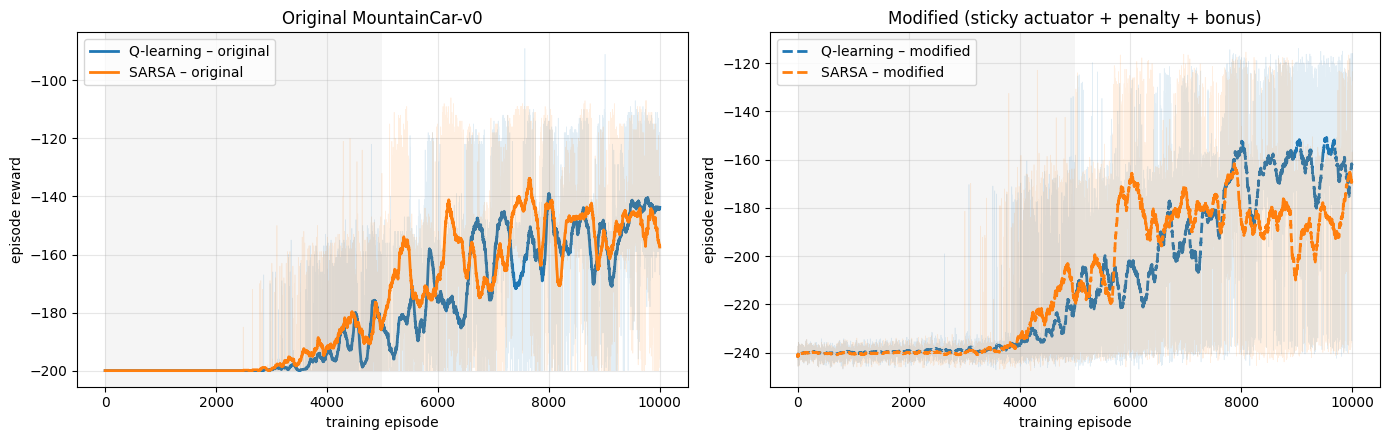

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
panels = [(axes[0], ["QL-orig", "SARSA-orig"], "Original MountainCar-v0"),
          (axes[1], ["QL-mod", "SARSA-mod"], "Modified (sticky actuator + penalty + bonus)")]
for ax, keys, title in panels:
    for k in keys:
        rew = HISTORY[k]["reward"].values
        ax.plot(rew, color=STYLE[k]["color"], alpha=0.12, lw=0.5)    # raw rewards (faint)
        ax.plot(moving_avg(rew), **STYLE[k], lw=2)                   # 100-episode average
    shade_decay(ax)
    ax.set_title(title)
    ax.set_xlabel("training episode")
    ax.set_ylabel("episode reward")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation (reward).**
* Both environments show a long flat phase at the start. In the original env the reward is exactly −200 (no success). In the modified env it is about −240, because a random agent selects a push in 2/3 of the steps: 200 × (−1 − 0.3·2/3) = −240. Learning starts only around episode 2500–3500, when ε has dropped enough for the agent to repeat a useful swing for many steps.
* **Original env:** SARSA improves a little earlier, but at the end the two are close. Over the last 500 training episodes Q-learning averages −143.6 and SARSA −150.4.
* **Modified env:** learning starts later and the curves are much noisier, because the same policy can give very different returns depending on how many commands get stuck. SARSA is ahead between roughly episodes 5500 and 7000, and Q-learning is ahead after about episode 7500 (last 500 episodes: −161.4 vs −180.1).
* The two panels are not directly comparable in absolute value: the modified reward adds −0.3 per push and +25 for a gentle arrival.

### (d.2) Average predicted value  max_a Q(s,a)  on the fixed validation states

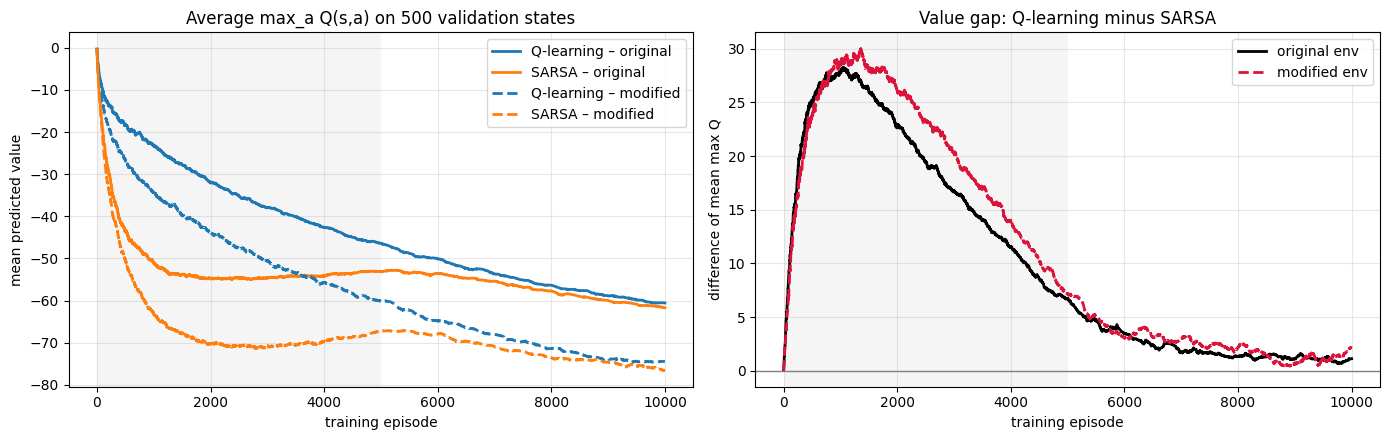

Mean value gap (Q-learning - SARSA) per training phase, seed 103:
                     ep 0-2500  ep 2500-5000  ep 5000-7500  ep 7500-10000
gap original             23.29         12.73          3.27           1.26
gap modified             24.68         15.33          3.85           1.51
modified / original       1.06          1.20          1.18           1.19

peak gap: original = 28.24 (ep 1054), modified = 30.01 (ep 1360)
episodes where SARSA's value is above Q-learning's: original 0, modified 0
final mean max Q QL-orig    :   -60.56
final mean max Q SARSA-orig :   -61.70
final mean max Q QL-mod     :   -74.44
final mean max Q SARSA-mod  :   -76.57


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# left: mean max-Q of the four agents
for k in ORDER:
    axes[0].plot(HISTORY[k]["mean_max_q"].values, **STYLE[k], lw=2)
axes[0].set_title("Average max_a Q(s,a) on 500 validation states")
axes[0].set_ylabel("mean predicted value")

# right: gap between the algorithms in each environment (Q-learning minus SARSA)
gap_orig = HISTORY["QL-orig"]["mean_max_q"].values - HISTORY["SARSA-orig"]["mean_max_q"].values
gap_mod = HISTORY["QL-mod"]["mean_max_q"].values - HISTORY["SARSA-mod"]["mean_max_q"].values
axes[1].plot(gap_orig, color="black", ls="-", lw=2, label="original env")
axes[1].plot(gap_mod, color="crimson", ls="--", lw=2, label="modified env")
axes[1].axhline(0, color="grey", lw=1)
axes[1].set_title("Value gap: Q-learning minus SARSA")
axes[1].set_ylabel("difference of mean max Q")
for ax in axes:                                     # common formatting
    shade_decay(ax)
    ax.set_xlabel("training episode")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# average gap in four training phases (first two = ε decay, last two = ε fixed at 0.01)
PHASES = [(0, 2500), (2500, 5000), (5000, 7500), (7500, 10000)]
gap_table = pd.DataFrame({f"ep {lo}-{hi}": {"gap original": gap_orig[lo:hi].mean(),
                                            "gap modified": gap_mod[lo:hi].mean()}
                          for lo, hi in PHASES})
gap_table.loc["modified / original"] = gap_table.loc["gap modified"] / gap_table.loc["gap original"]
print("Mean value gap (Q-learning - SARSA) per training phase, seed 103:")
print(gap_table.round(2).to_string())
print(f"\npeak gap: original = {gap_orig.max():.2f} (ep {gap_orig.argmax()}), "
      f"modified = {gap_mod.max():.2f} (ep {gap_mod.argmax()})")
print(f"episodes where SARSA's value is above Q-learning's: original {(gap_orig < 0).sum()}, "
      f"modified {(gap_mod < 0).sum()}")
for k in ORDER:
    print(f"final mean max Q {k:11s}: {HISTORY[k]['mean_max_q'].iloc[-1]:8.2f}")

**Interpretation (Q-values).**
* All curves start at 0 (the zero initialisation is optimistic because every step costs at least −1) and go down as the agent learns how many steps it really needs.
* Q-learning is above SARSA in both environments for the whole run. This is what we expect: Q-learning bootstraps from max_a′ Q(s′,a′), while SARSA bootstraps from the action ε-greedy really took, which is often a random (worse) one while ε is large. The gap is largest at about episode 1000–1400 (28.2 original, 30.0 modified) and shrinks as ε decays. Once ε = 0.01, both targets are almost the same and the curves nearly meet.
* The modified-env values are about 14–15 lower at the end (−74.4 / −76.6 vs −60.6 / −61.7). Every push costs 0.3 more, and stuck commands make the swing slower. The +25 bonus is discounted over many steps, so it only partly compensates.
* For seed 103 the gap is larger in the modified environment in every phase of training (table above): about 6 % larger during the first 2500 episodes and about 18–20 % larger afterwards. Section d.8 checks this for three more seeds.

### (d.3) Success rate and gentle-arrival rate (moving average over the previous 100 episodes)
For the original environment the gentle-arrival rate is computed with the same criterion (x ≥ 0.5, v ≤ 0.03), even though the original reward does not pay a bonus for it.

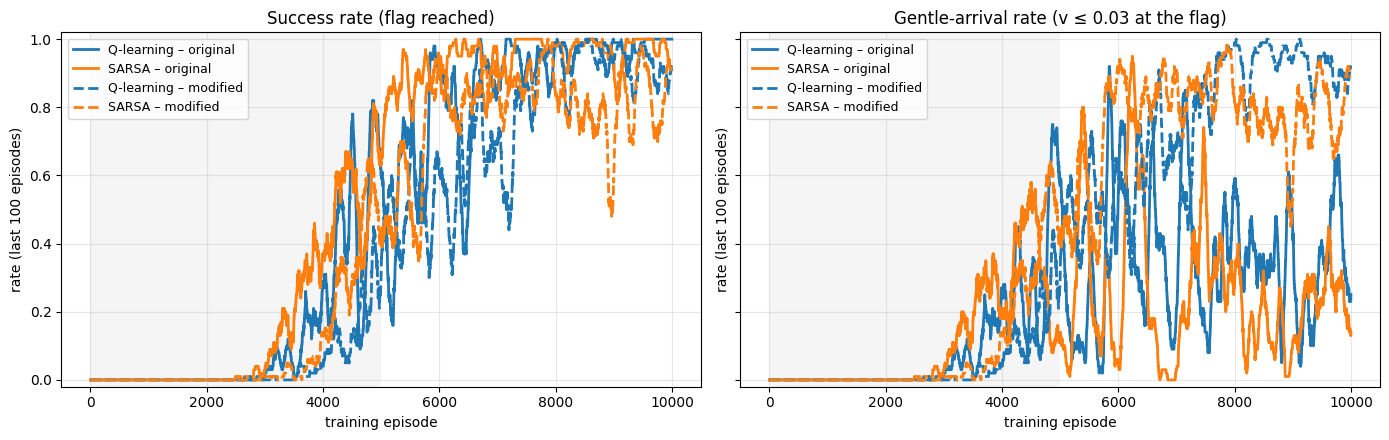

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
panels = [(axes[0], "success", "Success rate (flag reached)"),
          (axes[1], "gentle", "Gentle-arrival rate (v ≤ 0.03 at the flag)")]
for ax, col, title in panels:
    for k in ORDER:
        ax.plot(moving_avg(HISTORY[k][col]), **STYLE[k], lw=2)    # rate over last 100 episodes
    shade_decay(ax)
    ax.set_title(title)
    ax.set_xlabel("training episode")
    ax.set_ylabel("rate (last 100 episodes)")
    ax.set_ylim(-0.02, 1.02)
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation (success and gentle arrival).**
* **Success:** both original-env agents reach about 0.9–1.0 after roughly episode 6000–7500. The modified-env agents learn later and keep dipping, for example SARSA-modified drops to about 0.5 around episode 9000. With ε = 0.01 almost all randomness comes from the actuator, so even a good policy sometimes fails to reach the flag in 200 steps.
* **Gentle arrival:** this panel shows the clearest difference between the environments. For the modified agents the gentle-arrival curve almost copies the success curve: nearly every success is a gentle one. The original agents get no reward for arriving slowly, so their gentle-arrival rate just jumps around between 0 and about 0.6, depending on where the learned swing happens to end.
* Q-learning vs SARSA is less clear-cut here. In the original env SARSA reaches high success slightly earlier. In the modified env Q-learning is more stable at the end of training.

### (d.4) Average number of push actions (0 or 2) selected per episode

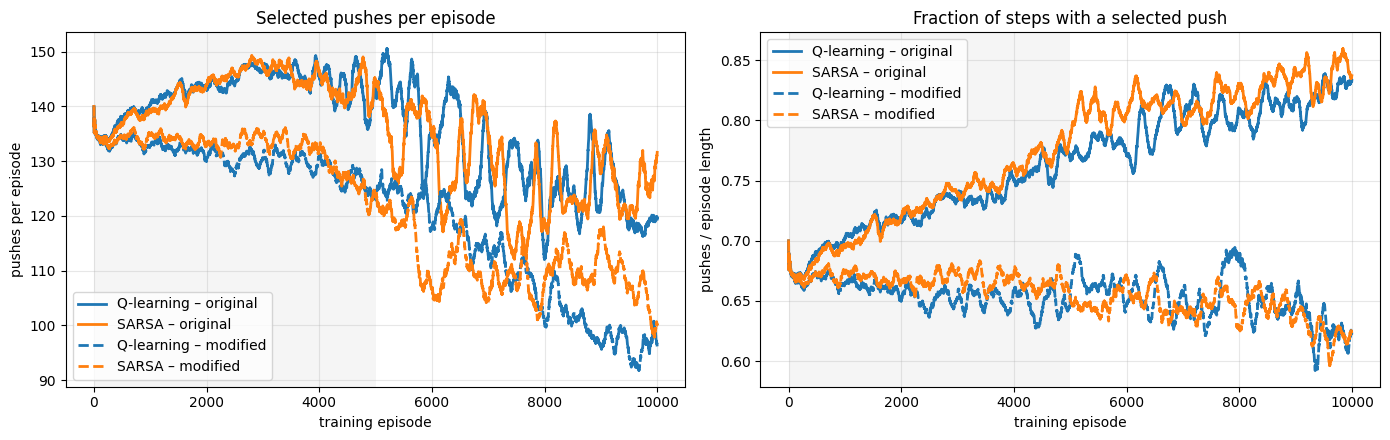

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for k in ORDER:
    pushes = HISTORY[k]["pushes"]
    axes[0].plot(moving_avg(pushes), **STYLE[k], lw=2)                             # count
    axes[1].plot(moving_avg(pushes / HISTORY[k]["length"]), **STYLE[k], lw=2)      # share
titles = [("Selected pushes per episode", "pushes per episode"),
          ("Fraction of steps with a selected push", "pushes / episode length")]
for ax, (t_, yl) in zip(axes, titles):
    shade_decay(ax)
    ax.set_title(t_)
    ax.set_xlabel("training episode")
    ax.set_ylabel(yl)
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation (push count).**
* At the start every agent selects about 135–140 pushes per episode, which is 2/3 of 200 random actions.
* **Original env:** pushes per episode first rise (episodes stay 200 steps long and the greedy part prefers pushing), then fall because the episodes become shorter. The *fraction* of steps with a push keeps increasing to about 0.84. Pushing is free, so the agent pushes almost all the time.
* **Modified env:** the fraction of push steps goes *down* from 0.67 to about 0.62, and at the end the agents select about 96–104 pushes per episode, against 119–127 in the original env. This is the effect of the energy penalty: the agent learns to coast (action 1) whenever pushing is not needed.
* Q-learning and SARSA behave very similarly here. The penalty, not the algorithm, decides the push count.

### (d.5) Greedy policy maps
Greedy action `argmax_a Q(s,a)` for every (position, velocity) bin. Bins that the agent never visited during training are white: their Q-values are still all zero, so their "greedy action" would only be numpy's tie-break (action 0) and would be misleading. The dashed line marks the flag (x = 0.5) and the dotted line the gentle-speed limit (v = 0.03).

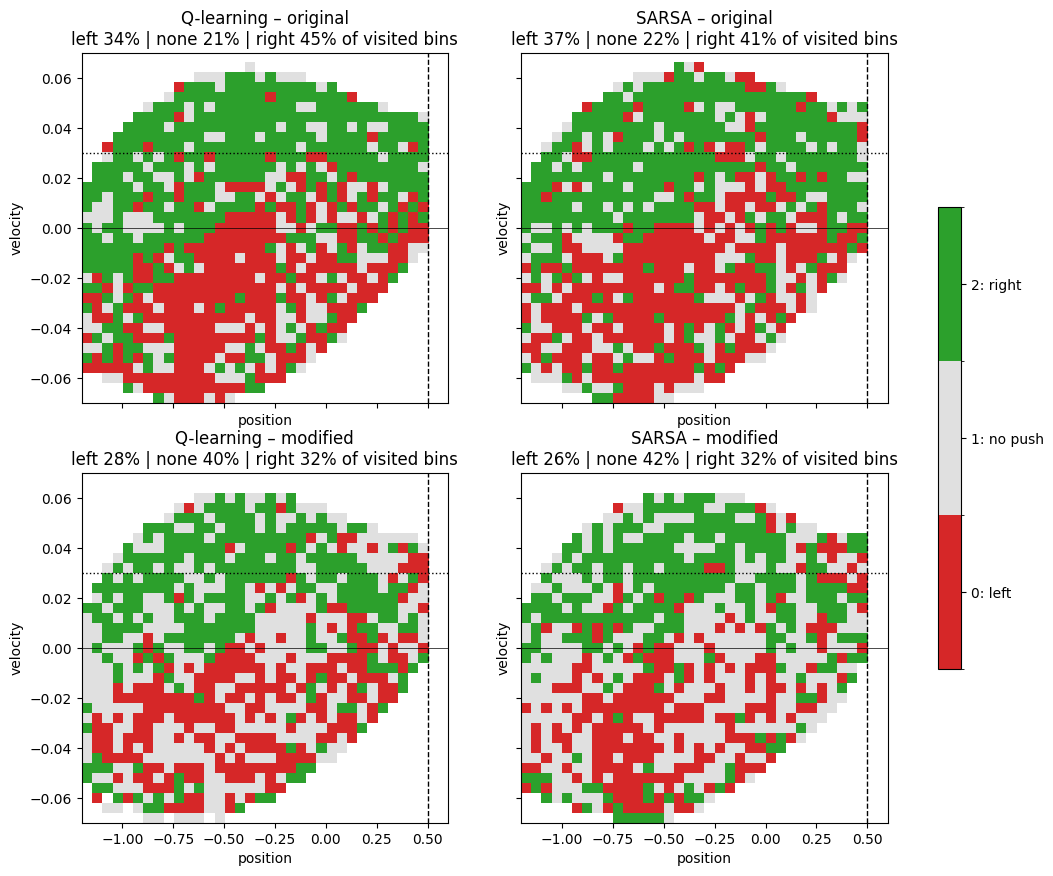

Greedy action share in the region x >= 0.2, v > 0.03 (approaching the flag too fast):
                       visited bins  left (brake)  no push  right (accelerate)
Q-learning – original          26.0          0.08     0.23                0.69
SARSA – original               31.0          0.13     0.26                0.61
Q-learning – modified          24.0          0.29     0.62                0.08
SARSA – modified               25.0          0.28     0.36                0.36


In [48]:
cmap = ListedColormap(["#d62728", "#e0e0e0", "#2ca02c"])   # red = left, grey = none, green = right
cmap.set_bad("white")                                     # colour of unvisited bins
norm = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap.N)          # one colour per action

fig, axes = plt.subplots(2, 2, figsize=(13, 10), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), ORDER):
    ag = AGENTS[k]
    greedy_all = np.argmax(ag.Q, axis=2)                   # greedy action in every bin
    greedy_map = greedy_all.astype(float)
    greedy_map[ag.visits == 0] = np.nan                    # hide never visited bins
    im = ax.imshow(greedy_map.T, origin="lower", aspect="auto", cmap=cmap, norm=norm,
                   extent=[OBS_LOW[0], OBS_HIGH[0], OBS_LOW[1], OBS_HIGH[1]])  # x=pos, y=vel
    ax.axvline(0.5, color="black", ls="--", lw=1)          # flag
    ax.axhline(0.03, color="black", ls=":", lw=1)          # gentle speed limit
    ax.axhline(0.0, color="black", lw=0.5)                 # zero velocity
    visited = ag.visits > 0
    share = [np.mean(greedy_all[visited] == a) for a in range(3)]   # action mix of visited bins
    ax.set_title(f"{STYLE[k]['label']}\nleft {share[0]:.0%} | none {share[1]:.0%} | "
                 f"right {share[2]:.0%} of visited bins")
    ax.set_xlabel("position")
    ax.set_ylabel("velocity")
cbar = fig.colorbar(im, ax=axes.ravel().tolist(), ticks=[0, 1, 2], shrink=0.6)
cbar.ax.set_yticklabels(["0: left", "1: no push", "2: right"])
plt.show()

# action mix just before the flag where the car is too fast for a gentle arrival
nb_x, nb_v = CONFIG["n_bins"]
pos_c = OBS_LOW[0] + (np.arange(nb_x) + 0.5) * (OBS_HIGH[0] - OBS_LOW[0]) / nb_x   # bin centres
vel_c = OBS_LOW[1] + (np.arange(nb_v) + 0.5) * (OBS_HIGH[1] - OBS_LOW[1]) / nb_v
region = (pos_c[:, None] >= 0.2) & (vel_c[None, :] > 0.03)                       # x>=0.2, v>0.03
rows = {}
for k in ORDER:
    ag = AGENTS[k]
    mask = region & (ag.visits > 0)                       # visited bins inside the region
    g = np.argmax(ag.Q, axis=2)[mask]
    rows[STYLE[k]["label"]] = {"visited bins": int(mask.sum()), "left (brake)": np.mean(g == 0),
                               "no push": np.mean(g == 1), "right (accelerate)": np.mean(g == 2)}
print("Greedy action share in the region x >= 0.2, v > 0.03 (approaching the flag too fast):")
print(pd.DataFrame(rows).T.round(2).to_string())

**Interpretation (policy maps).**
* **Original env:** both maps show the classic energy-pumping policy: accelerate right (green) when the velocity is positive and left (red) when it is negative. Only about 21–22 % of the visited bins choose "no push".
* **Modified env:** the share of "no push" bins doubles to 40–42 %, mainly around zero velocity and in the low-speed part of the valley, where pushing helps little but always costs 0.3.
* **Near the flag:** the region x ≥ 0.2, v > 0.03 (table above) shows the effect of the bonus most clearly. The original agents mostly keep accelerating there (69 % / 61 % right). The modified Q-learning agent accelerates in only 8 % of those bins and brakes or coasts in the rest. SARSA-modified also brakes or coasts much more (64 %), but less consistently.
* The maps are noisy, especially at the edges, because those bins are visited rarely. This is a typical limitation of tabular methods.

### (d.6) Final greedy policies (ε = 0) – 100 test episodes with fixed seeds
Each agent is tested in the environment it was trained in. Test seeds are 20 000 … 20 099 (never used in training); in the modified env the same seed also fixes the actuator noise, so every agent faces exactly the same random situations.

In [51]:
def evaluate_greedy(agent, modified, n_episodes=100, seed0=20_000):
    '''Run the greedy policy (ε = 0) and return per-episode results as a DataFrame.'''
    env = make_env(modified)
    rows = []
    for i in range(n_episodes):
        obs, _ = env.reset(seed=seed0 + i)                  # fixed test seed
        total, steps, pushes = 0.0, 0, 0
        while True:
            a = agent.greedy(agent.state(obs))              # ε = 0, always the best action
            pushes += int(a != 1)                           # count selected pushes
            obs, R, term, trunc, _ = env.step(a)
            total += R
            steps += 1
            if term or trunc:
                break
        gentle = bool(term and obs[0] >= 0.5 and obs[1] <= 0.03)
        rows.append(dict(reward=total, success=term, gentle=gentle, length=steps,
                         pushes=pushes, arrival_v=float(obs[1]) if term else np.nan))
    env.close()
    return pd.DataFrame(rows)


def eval_summary(d):
    '''One row of the results table from the per-episode test results.'''
    return {"mean reward": d["reward"].mean(), "std reward": d["reward"].std(),
            "success rate": d["success"].mean(), "gentle-arrival rate": d["gentle"].mean(),
            "mean episode length": d["length"].mean(), "mean pushes": d["pushes"].mean(),
            "mean arrival v": d["arrival_v"].mean()}


EVAL = {k: evaluate_greedy(AGENTS[k], modified=k.endswith("mod")) for k in ORDER}
eval_table = pd.DataFrame({STYLE[k]["label"]: eval_summary(d) for k, d in EVAL.items()}).T
print(eval_table.round(3).to_string())
stamp("Greedy evaluation finished")

                       mean reward  std reward  success rate  gentle-arrival rate  mean episode length  mean pushes  mean arrival v
Q-learning – original     -143.480      14.684          1.00                 0.32               143.48       116.22           0.035
SARSA – original          -162.190      21.134          0.93                 0.00               162.19       136.16           0.038
Q-learning – modified     -149.807      29.968          0.95                 0.95               146.40        89.69           0.016
SARSA – modified          -176.800      38.779          0.81                 0.76               163.93       105.40           0.021
[2026-11-01 11:34:09] host=ip-10-3-24-18.ap-south-1.compute.internal | Greedy evaluation finished


**Arrival-speed statistics** (used in Part e): distribution of the velocity at the moment the flag is reached, greedy test episodes.

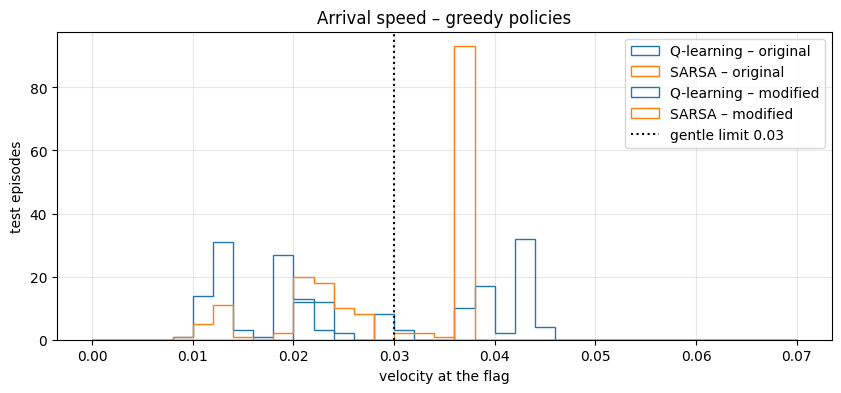

                       arrivals  mean v  median v   min v   max v  share v<=0.03
Q-learning – original     100.0  0.0352    0.0382  0.0209  0.0443         0.3200
SARSA – original           93.0  0.0375    0.0375  0.0375  0.0375         0.0000
Q-learning – modified      95.0  0.0161    0.0143  0.0092  0.0248         1.0000
SARSA – modified           81.0  0.0213    0.0220  0.0089  0.0354         0.9383


In [53]:
speed_rows = {}
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.linspace(0, 0.07, 36)                            # histogram bins for the speed
for k in ORDER:
    v = EVAL[k]["arrival_v"].dropna()                      # only episodes that reached the flag
    speed_rows[STYLE[k]["label"]] = {"arrivals": len(v), "mean v": v.mean(),
                                     "median v": v.median(), "min v": v.min(),
                                     "max v": v.max(), "share v<=0.03": (v <= 0.03).mean()}
    ax.hist(v, bins=bins, histtype="step", lw=2, color=STYLE[k]["color"], ls=STYLE[k]["ls"],
            label=STYLE[k]["label"])
ax.axvline(0.03, color="black", ls=":", label="gentle limit 0.03")
ax.set_xlabel("velocity at the flag")
ax.set_ylabel("test episodes")
ax.set_title("Arrival speed – greedy policies")
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(pd.DataFrame(speed_rows).T.round(4).to_string())

**Interpretation (greedy test, ε = 0).**
* **Original env:** Q-learning reaches the flag in all 100 test episodes with a mean length of 143.5 steps. SARSA succeeds in 93 % of the episodes and needs 162 steps on average.
* **Modified env:** Q-learning has 95 % success and 95 % gentle arrivals (every arrival was gentle). SARSA has 81 % success and 76 % gentle arrivals. The standard deviation of the reward is about twice as high as in the original env, which again shows the effect of the actuator noise.
* **Arrival speed:** the histogram shows the effect of the reward design directly. The original agents arrive at 0.035–0.038 on average, above the 0.03 limit. SARSA-original even arrives at almost the same speed (0.0375) every time, because its deterministic swing always ends the same way. The modified agents arrive at 0.016 (Q-learning) and 0.021 (SARSA), clearly below the limit.
* **Pushes:** the modified agents also use fewer pushes per test episode (90 / 105 vs 116 / 136).

### (d.7) Extra – robustness check: all four agents tested in the sticky environment
The agents trained in the original environment never experienced the stuck actuator. Testing every agent in the modified environment (same 100 seeds) shows how much training under sticky actuators actually matters. All rewards here are on the modified-reward scale, so they can be compared directly.

In [56]:
# every agent is tested in the MODIFIED env with the same 100 seeds
cross = {STYLE[k]["label"]: evaluate_greedy(AGENTS[k], modified=True) for k in ORDER}
cross_table = pd.DataFrame({n: eval_summary(d) for n, d in cross.items()}).T
print(cross_table.drop(columns=["std reward"]).round(3).to_string())

                       mean reward  success rate  gentle-arrival rate  mean episode length  mean pushes  mean arrival v
Q-learning – original     -170.571          1.00                 0.32               143.06       118.37           0.035
SARSA – original          -204.125          0.89                 0.02               163.84       135.95           0.039
Q-learning – modified     -149.807          0.95                 0.95               146.40        89.69           0.016
SARSA – modified          -176.800          0.81                 0.76               163.93       105.40           0.021


**Interpretation (cross-test).**
* Under the stuck actuator, the original-env Q-learning agent still reaches the flag every time, but it arrives fast. Only 32 % of its arrivals are gentle, and it pushes a lot, so its modified-reward score is −170.6 instead of −149.8 for the agent trained in the modified env.
* SARSA-original loses some success (0.93 → 0.89) and almost never arrives gently (2 %), giving −204.1 vs −176.8.
* So the swing-up skill itself is quite robust to a 30 % sticky actuator. What the agents really gain from training in the modified environment is the behaviour the new reward asks for: fewer pushes and a slow arrival.

### (d.8) Extra – is the result stable across seeds?
One seed can be lucky. We repeat the whole training for three more seeds (7, 42, 2024) with exactly the same configuration, and report the greedy test results and the value gap for all four seeds (including 103). Progress printing is switched off here to keep the report short. *(This took about 27 minutes in the virtual lab.)*

In [59]:
extra_seeds = [7, 42, 2024]
SEED_HIST = {103: HISTORY}                       # training histories per seed (103 = main runs)
seed_rows = []
for k in ORDER:                                  # greedy results of seed 103 from the main runs
    seed_rows.append(dict(agent=STYLE[k]["label"], seed=103, **eval_summary(EVAL[k])))
for sd in extra_seeds:
    cfg_s = dict(CONFIG, seed=sd)                # identical config, only the seed changes
    SEED_HIST[sd] = {}
    for k in ORDER:
        method = "qlearning" if k.startswith("QL") else "sarsa"
        mod = k.endswith("mod")
        ag, h = train_agent(method, mod, cfg=cfg_s, verbose=False)
        SEED_HIST[sd][k] = h                     # keep the history for the value-gap analysis
        seed_rows.append(dict(agent=STYLE[k]["label"], seed=sd,
                              **eval_summary(evaluate_greedy(ag, mod))))
    stamp(f"seed {sd} done")

seed_df = pd.DataFrame(seed_rows)
labels = [STYLE[k]["label"] for k in ORDER]
print("Greedy test mean reward per seed:")
print(seed_df.pivot(index="agent", columns="seed", values="mean reward").loc[labels]
      .round(2).to_string())
agg = seed_df.groupby("agent").agg(reward_mean=("mean reward", "mean"),
                                   reward_std=("mean reward", "std"),
                                   success_mean=("success rate", "mean"),
                                   gentle_mean=("gentle-arrival rate", "mean"))
print("\nMean over 4 seeds:")
print(agg.loc[labels].round(3).to_string())

[2026-11-01 11:43:10] host=ip-10-3-24-18.ap-south-1.compute.internal | seed 7 done
[2026-11-01 11:52:00] host=ip-10-3-24-18.ap-south-1.compute.internal | seed 42 done
[2026-11-01 12:00:46] host=ip-10-3-24-18.ap-south-1.compute.internal | seed 2024 done
Greedy test mean reward per seed:
seed                     7       42      103     2024
agent                                                
Q-learning – original -142.83 -137.94 -143.48 -134.35
SARSA – original      -139.72 -149.86 -162.19 -149.41
Q-learning – modified -161.00 -173.56 -149.81 -196.43
SARSA – modified      -157.98 -162.93 -176.80 -200.67

Mean over 4 seeds:
                       reward_mean  reward_std  success_mean  gentle_mean
agent                                                                    
Q-learning – original     -139.650       4.313         0.985        0.495
SARSA – original          -150.295       9.207         0.978        0.165
Q-learning – modified     -170.198      19.998         0.855        0.847

In [60]:
# value gap (Q-learning minus SARSA) per phase for every seed, original vs modified env
gap_rows = []
for sd, H in SEED_HIST.items():
    g_o = H["QL-orig"]["mean_max_q"].values - H["SARSA-orig"]["mean_max_q"].values
    g_m = H["QL-mod"]["mean_max_q"].values - H["SARSA-mod"]["mean_max_q"].values
    for lo, hi in PHASES:
        gap_rows.append(dict(seed=sd, phase=f"ep {lo}-{hi}", gap_original=g_o[lo:hi].mean(),
                             gap_modified=g_m[lo:hi].mean()))
    gap_rows.append(dict(seed=sd, phase="SARSA above QL (episodes)",
                         gap_original=(g_o < 0).sum(), gap_modified=(g_m < 0).sum()))
gap_seed = pd.DataFrame(gap_rows)
gap_seed["ratio mod/orig"] = gap_seed["gap_modified"] / gap_seed["gap_original"]
phase_only = gap_seed[gap_seed["phase"].str.startswith("ep")]
print(phase_only.pivot(index="phase", columns="seed", values="ratio mod/orig").round(2)
      .to_string())
print("\nMean over the 4 seeds:")
print(phase_only.groupby("phase")[["gap_original", "gap_modified"]].mean()
      .assign(ratio=lambda d: d["gap_modified"] / d["gap_original"]).round(2).to_string())
above = gap_seed[gap_seed["phase"].str.startswith("SARSA")]
print("\nEpisodes in which SARSA's mean max-Q was above Q-learning's:")
print(above[["seed", "gap_original", "gap_modified"]].to_string(index=False))

seed           7     42    103   2024
phase                                
ep 0-2500      1.02  1.01  1.06  1.05
ep 2500-5000   1.21  1.23  1.20  1.17
ep 5000-7500   1.29  1.22  1.18  1.24
ep 7500-10000  1.16  1.15  1.19  1.47

Mean over the 4 seeds:
               gap_original  gap_modified  ratio
phase                                           
ep 0-2500             23.60         24.42   1.03
ep 2500-5000          12.85         15.47   1.20
ep 5000-7500           3.14          3.87   1.23
ep 7500-10000          1.32          1.65   1.25

Episodes in which SARSA's mean max-Q was above Q-learning's:
 seed  gap_original  gap_modified
  103           0.0           0.0
    7           0.0          63.0
   42           0.0           0.0
 2024           0.0           0.0


**Interpretation (seeds).**
* **Original env:** Q-learning has a better greedy test reward than SARSA on 3 of the 4 seeds, and its result changes little between seeds (std 4.3).
* **Modified env:** the ranking depends on the seed. Q-learning is better on seeds 103 and 2024, and SARSA is better on seeds 7 and 42. The means over the 4 seeds (−170.2 vs −174.6) differ by much less than the seed-to-seed standard deviation (about 20).
  * So we **cannot claim that one algorithm is clearly better under sticky actuators**. The large difference seen with seed 103 alone (−149.8 vs −176.8) is partly luck.
* **Reliability:** the spread between seeds is about 2–5 times larger in the modified env than in the original env. This is another sign that the sticky actuator makes learning much less reliable.
* **Value gap:** unlike the performance ranking, the value-gap result is consistent across seeds. For every seed and every phase, the Q-learning–SARSA gap is larger in the modified environment (ratios 1.01–1.47). This is used in Q1.

In [62]:
stamp("Part (d) finished")   # time stamp for the screenshot

[2026-11-01 12:00:46] host=ip-10-3-24-18.ap-south-1.compute.internal | Part (d) finished


---
# Part (e) – Discussion

### Q1. Does the sticky actuator increase the difference between the value estimates of Q-learning and SARSA?

**Yes, but only moderately. The effect is clearest in the middle and late phases of training.**

Evidence from the value-gap plot (d.2) and the four-seed table (d.8):
* **Ordering:** Q-learning's average max-Q is above SARSA's in both environments, as expected (max ≥ the value of the action ε-greedy actually takes). SARSA was never above Q-learning in the original env. In the modified env this happened only for one seed (seed 7, in 63 of 10 000 episodes).
* **Seed 103:** the gap is larger in the modified environment in every training phase: 24.7 vs 23.3 (episodes 0–2500), 15.3 vs 12.7 (2500–5000), 3.9 vs 3.3 (5000–7500) and 1.5 vs 1.3 (7500–10000).
* **Four seeds:** every seed shows the same pattern. All 16 ratios (modified gap / original gap) are above 1, from 1.01 to 1.47. Averaged over the four seeds the gap is 3 % larger in the first phase and 20–25 % larger in the later phases.
* **Absolute size:** once ε is small (0.01), the two targets almost coincide, so the absolute gap at the end is only about 1–2 (out of values around −60 to −77) in both environments.

Why the gap is larger, as we understand it:
* SARSA's target uses the action that is really taken next, so its values include the cost of its own random actions.
* With a sticky actuator a random or badly timed switch costs more. The command may be ignored, or the old command keeps acting, so a wrong decision is harder to correct quickly. SARSA's on-policy values are pulled down further.
* Q-learning's target assumes the best next action and does not include this exploration cost.

### Q2. Why is the modified environment non-Markovian with respect to the observation, and how does this affect credit assignment?

* **The Markov property fails.** It requires that the next state and reward depend only on the current state and action. In the modified environment the next state depends on (x, v, a) and also on `a_prev`: if `a ≠ a_prev`, there is a 30 % chance that `a_prev` is executed instead. `a_prev` is part of the real state of the system, but it is not in the observation (x, v).
  * Two situations with the same (x, v) and the same selected action can therefore lead to different distributions of next states, depending on what the actuator did before.
  * From the agent's point of view, the same (observation, action) pair has different outcomes at different times.
* **Credit assignment is affected in three ways:**
  1. **Wrong action credited.** The update is applied to Q(s, a) for the *selected* action, but the transition was sometimes produced by `a_prev`. Part of the time, an action gets credit or blame for an outcome caused by the previous action.
  2. **Mixed outcomes per state.** Since `a_prev` is hidden, Q(s, a) learns an average over "actuator was on the same action" and "actuator was on a different action". Repeating the same action is safe (never stuck), while switching is risky. The table cannot represent this difference, because it does not know what the previous action was.
  3. **Delayed effects.** A decision now (to switch) can affect the next steps because the old action keeps being executed. This makes the TD error noisier and spreads credit over several steps.

  This is visible in our results: slower learning, noisier reward curves, more seed-to-seed variance (std ≈ 20 vs 4–9) and noisier policy maps. Theoretical convergence guarantees of both TD methods assume a Markov state, so they do not strictly hold here.

### Q3. Do the energy penalty and the gentle-arrival bonus encourage fewer pushes and a slower, more controlled arrival?

**Yes, both effects are clearly visible.**

| measure | original env | modified env |
|---|---|---|
| pushes per episode, end of training (push plot) | ~119–127 | ~96–104 |
| fraction of steps with a push | rises to 0.84 | falls to ~0.62 |
| "no push" share of visited bins (policy maps) | 21–22 % | 40–42 % |
| greedy action "accelerate" in x ≥ 0.2, v > 0.03 | 69 % / 61 % | 8 % / 36 % |
| mean arrival velocity, greedy test | 0.035 / 0.038 | 0.016 / 0.021 |
| arrivals with v ≤ 0.03 | 32 % / 0 % | 100 % / 94 % |
| mean pushes per greedy test episode | 116 / 136 | 90 / 105 |

(Where two numbers are given, they are Q-learning / SARSA.)

* **Fewer pushes:** the penalty makes "do nothing" the preferred action whenever pushing is not needed.
* **Slower arrival:** near the flag, the modified agents brake or coast instead of accelerating, so the bonus clearly shapes the final approach.
* **The two terms work together.** Arriving slowly needs fewer pushes at the end, and avoiding pushes makes the car arrive more slowly.
* **Small price:** the modified agents need about as many steps (146 vs 143 for Q-learning) or slightly more, because a gentle approach takes a bit more time.

### Q4. Which algorithm performs better under sticky actuators? Is this consistent with the theory?

**For seed 103, Q-learning performed better** in the modified environment:

| (seed 103, greedy test) | Q-learning | SARSA |
|---|---|---|
| mean reward | −149.8 | −176.8 |
| success | 95 % | 81 % |
| gentle arrivals | 95 % | 76 % |

**Over four seeds the picture is mixed:** Q-learning wins on two seeds and SARSA on two, and the mean difference (−170.2 vs −174.6) is far smaller than the standard deviation between seeds (~20). Our honest conclusion is that **neither algorithm is clearly better** in this setting, with a slight edge for Q-learning.

This is consistent with the theory once we look at what the theory actually says:
* **Different targets.** SARSA (on-policy) learns the value of the ε-greedy policy it follows. Q-learning (off-policy) learns the value of the greedy policy, whatever the behaviour policy does. SARSA is therefore "safer" when *exploratory* actions are dangerous (the cliff-walking example), because it includes the cost of its own exploration in the values.
* **The actuator noise reaches both.** The sticky actuator is part of the environment's transition dynamics, so both algorithms experience it through the sampled next state s′. Q-learning's max does not hide the actuator noise, it only ignores the noise from the agent's own ε-exploration.
* **The targets become almost the same.** In our schedule ε falls to 0.01, so SARSA's target is almost Q-learning's target in the second half of training, and the final greedy policies end up similar. The on-policy/off-policy difference appears mainly in the *value estimates during exploration* (Q-value plot, Q1), not in the final greedy performance.
* **No guarantees here.** The modified problem is non-Markovian in the observation (Q2), so neither method has a convergence guarantee, and the result depends strongly on the random seed. This is what we observe.

### Q5. One limitation and one possible improvement

* **Limitation:** the agent's state is only the discretised (x, v). It does not contain any information about the actuator (the previous action), so the problem is non-Markovian for the agent (Q2). Together with a constant learning rate, this makes the learned values noisy: the policy maps contain isolated "wrong" cells and the results vary strongly between seeds.
* **Improvement:** add the agent's own *previously selected* action to the state, giving a table of size 36 × 35 × 3 × 3. The agent always knows its own last choice, so this does not expose any hidden information from the environment. Because the actuator only gets stuck when the action changes, knowing the last selected action tells the agent whether switching now is risky. This makes the state much closer to Markov and should reduce the noise in credit assignment.
* **Further improvement:** use more seeds (we used only 4, which was not enough to separate Q-learning and SARSA in the modified env) and possibly a decaying learning rate. That would make the comparison between the algorithms statistically meaningful.

---
# Appendix A – re-check of the chosen bins and α
To check the chosen configuration we compared it with a few other grid sizes and learning rates on the **modified** environment (seed 103, otherwise the same settings as above). The table shows the greedy test results (100 episodes, same test seeds as in d.6). This is only a small check with one seed, not a full tuning study.

In [65]:
# small check of grid size and learning rate on the modified environment
variants = [("25 x 25, α=0.15", (25, 25), 0.15),
            ("36 x 35, α=0.10", (36, 35), 0.10),
            ("36 x 35, α=0.15 (used)", (36, 35), 0.15),
            ("50 x 50, α=0.15", (50, 50), 0.15)]
app_rows = []
for label, nb, lr in variants:
    cfg_v = dict(CONFIG, n_bins=nb, alpha=lr)        # only bins / α change
    for method in ("qlearning", "sarsa"):
        ag, h = train_agent(method, True, cfg=cfg_v, verbose=False)
        res = eval_summary(evaluate_greedy(ag, True))
        app_rows.append(dict(variant=label, method=method,
                             last500_train_reward=h["reward"].tail(500).mean(),
                             test_reward=res["mean reward"], success=res["success rate"],
                             gentle=res["gentle-arrival rate"]))
    stamp(f"variant {label} done")
print(pd.DataFrame(app_rows).round(3).to_string(index=False))

[2026-11-01 12:05:18] host=ip-10-3-24-18.ap-south-1.compute.internal | variant 25 x 25, α=0.15 done
[2026-11-01 12:09:49] host=ip-10-3-24-18.ap-south-1.compute.internal | variant 36 x 35, α=0.10 done
[2026-11-01 12:14:18] host=ip-10-3-24-18.ap-south-1.compute.internal | variant 36 x 35, α=0.15 (used) done
[2026-11-01 12:18:57] host=ip-10-3-24-18.ap-south-1.compute.internal | variant 50 x 50, α=0.15 done
               variant    method  last500_train_reward  test_reward  success  gentle
       25 x 25, α=0.15 qlearning              -168.116     -184.711     0.78    0.78
       25 x 25, α=0.15     sarsa              -202.505     -168.512     0.93    0.93
       36 x 35, α=0.10 qlearning              -168.553     -165.294     0.94    0.94
       36 x 35, α=0.10     sarsa              -172.301     -175.520     0.86    0.84
36 x 35, α=0.15 (used) qlearning              -161.362     -149.807     0.95    0.95
36 x 35, α=0.15 (used)     sarsa              -180.112     -176.800     0.81    0.7

**Interpretation (Appendix A).**
* **Best average:** averaged over both algorithms, the chosen setting (36 × 35, α = 0.15) gave the best greedy test reward (Q-learning −149.8, SARSA −176.8, mean −163.3).
  * 36 × 35 with α = 0.10 came next (mean −170.4): a little better for SARSA, clearly worse for Q-learning.
  * 25 × 25 had a mean of −176.6. SARSA did well there (−168.5, 93 % success), but Q-learning was poor (78 % success).
* **Too many bins:** 50 × 50 was the worst for both algorithms (mean −186.8, success 0.68–0.80). With 2500 states each bin is visited less often, so 10 000 episodes are not enough to fill the table.
* **Caveat:** this is a single seed, and the differences between the first three settings are of the same size as the seed-to-seed spread in d.8. So we see it as support for the choice, not as proof that it is the best possible setting.

In [67]:
stamp("Notebook finished")   # final time stamp

[2026-11-01 12:18:57] host=ip-10-3-24-18.ap-south-1.compute.internal | Notebook finished
